In [1]:
import cv2 # opencv-python
import numpy as np
from pathlib import Path

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
def detect_markers(frame):
    """
    Detect the largest red and green blobs in the frame.
    Returns:
        (rx, ry, gx, gy, combined_mask, annotated_frame)
    """
    annotated = frame.copy()
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    # --- ROOD DETECTIE ---
    # HSV waarden iets ruimer gezet om de vervaagde rode stip beter te pakken
    lower_red1 = np.array([0, 80, 50])
    upper_red1 = np.array([10, 255, 255])

    lower_red2 = np.array([170, 80, 50])
    upper_red2 = np.array([180, 255, 255])

    mask_red1 = cv2.inRange(hsv, lower_red1, upper_red1)
    mask_red2 = cv2.inRange(hsv, lower_red2, upper_red2)
    mask_red = cv2.bitwise_or(mask_red1, mask_red2)

    # --- GROEN DETECTIE ---
    lower_green = np.array([25, 15, 50])
    upper_green = np.array([100, 255, 255])
    mask_green = cv2.inRange(hsv, lower_green, upper_green)

    # Opschonen van maskers
    kernel = np.ones((5, 5), np.uint8)
    mask_red = cv2.morphologyEx(mask_red, cv2.MORPH_OPEN, kernel)
    mask_red = cv2.morphologyEx(mask_red, cv2.MORPH_CLOSE, kernel)
    
    mask_green = cv2.morphologyEx(mask_green, cv2.MORPH_OPEN, kernel)
    mask_green = cv2.morphologyEx(mask_green, cv2.MORPH_CLOSE, kernel)

    def get_center(mask, draw_color, label):
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        # Alleen een minimumgrootte om ruis te filteren. Bovengrens is verwijderd.
        valid_contours = [c for c in contours if cv2.contourArea(c) >= 10]
        
        if not valid_contours:
            return None, None
            
        largest = max(valid_contours, key=cv2.contourArea)
        M = cv2.moments(largest)
        if M["m00"] == 0:
            return None, None

        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])

        cv2.circle(annotated, (cx, cy), 6, draw_color, -1)
        cv2.drawContours(annotated, [largest], -1, draw_color, 2)
        cv2.putText(annotated, f"{label}({cx}, {cy})", (cx + 10, cy - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, draw_color, 1, cv2.LINE_AA)
        
        return cx, cy

    rx, ry = get_center(mask_red, (0, 0, 255), "R")
    gx, gy = get_center(mask_green, (0, 255, 0), "G")

    combined_mask = cv2.bitwise_or(mask_red, mask_green)
    
    return rx, ry, gx, gy, combined_mask, annotated

In [29]:
def process_video(video_path, output_csv, preview=True, save_annotated=False):
    video_path = Path(video_path)
    if not video_path.exists():
        raise FileNotFoundError(f"Video file not found: {video_path}")

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    writer = None
    if save_annotated:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        annotated_path = video_path.with_name(video_path.stem + "_tracked1.mp4")
        writer = cv2.VideoWriter(str(annotated_path), fourcc, fps, (width, height))

    results = []
    frame_idx = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        rx, ry, gx, gy, mask, annotated = detect_markers(frame)

        time_s = frame_idx / fps if fps > 0 else np.nan

        results.append({
            "frame": frame_idx,
            "time_s": time_s,
            "red_x": rx,
            "red_y": ry,
            "green_x": gx,
            "green_y": gy
        })

        if writer is not None:
            writer.write(annotated)

        if preview:
            combined_mask = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
            top = np.hstack((frame, annotated))
            bottom = np.hstack((combined_mask, np.zeros_like(combined_mask)))
            display = np.vstack((top, bottom))

            scale = 0.7
            display = cv2.resize(display, None, fx=scale, fy=scale)

            cv2.imshow("Original | Annotated / Mask", display)

            key = cv2.waitKey(1) & 0xFF
            if key == ord("q"):
                break

        frame_idx += 1

    cap.release()
    if writer is not None:
        writer.release()
    cv2.destroyAllWindows()

    df = pd.DataFrame(results)
    df.to_csv(output_csv, index=False)

    print(f"Done. Saved coordinates to: {output_csv}")
    if save_annotated:
        print(f"Saved annotated video to: {annotated_path}")

    missing_red = df["red_x"].isna().sum()
    missing_green = df["green_x"].isna().sum()
    print(f"Frames processed: {len(df)}")
    print(f"Frames with missing red detection: {missing_red}")
    print(f"Frames with missing green detection: {missing_green}")

In [30]:

video = r"C:\Users\Vera Reeringh\OneDrive - Delft University of Technology\Technische Natuurkunde\Jaar 2\Onderzoekspracticum Q1\slingerproef\test90graden.mp4"
output = "90gradentest3.csv"

process_video(
        video_path=video,
        output_csv=output,
        preview=True,
        save_annotated=True
    )



Done. Saved coordinates to: 90gradentest3.csv
Saved annotated video to: C:\Users\Vera Reeringh\OneDrive - Delft University of Technology\Technische Natuurkunde\Jaar 2\Onderzoekspracticum Q1\slingerproef\test90graden_tracked1.mp4
Frames processed: 1341
Frames with missing red detection: 13
Frames with missing green detection: 2


In [31]:
def export_first_frame(
    video_path,
    output_png=None,
    dpi=300
):
    """
    Export the first frame of a video as a PNG.

    The exported image keeps exactly the same pixel width and height
    as the original video frame.

    Parameters
    ----------
    video_path : str or Path
        Path to the input video.

    output_png : str or Path, optional
        Output PNG path. If None, the output name will be:
        <video_name>_first_frame.png

    dpi : float
        DPI metadata written to the PNG.
        DPI does not change the number of pixels or image quality.
    """

    video_path = Path(video_path)

    if not video_path.exists():
        raise FileNotFoundError(
            f"Video file not found: {video_path}"
        )

    if output_png is None:
        output_png = video_path.with_name(
            video_path.stem + "_first_frame.png"
        )
    else:
        output_png = Path(output_png)

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    success, frame = cap.read()
    cap.release()

    if not success or frame is None:
        raise RuntimeError(
            "Could not read the first frame from the video."
        )

    height, width = frame.shape[:2]

    # OpenCV writes the original pixel data without resizing.
    success = cv2.imwrite(
        str(output_png),
        frame,
        [cv2.IMWRITE_PNG_COMPRESSION, 3]
    )

    if not success:
        raise RuntimeError(
            f"Could not save PNG: {output_png}"
        )

    # OpenCV does not reliably write DPI metadata, so add it using Pillow.
    try:
        from PIL import Image

        with Image.open(output_png) as image:
            image.save(
                output_png,
                dpi=(dpi, dpi)
            )

    except ImportError:
        print(
            "Pillow is not installed, so DPI metadata was not added."
        )
        print(
            "Install it with: pip install pillow"
        )

    print(f"Saved first frame to: {output_png}")
    print(f"Resolution: {width} x {height} pixels")
    print(f"DPI metadata: {dpi} DPI")

    return output_png

In [32]:
export_first_frame(
    video_path=video,
    output_png=None,
    dpi=300
)

Saved first frame to: C:\Users\Vera Reeringh\OneDrive - Delft University of Technology\Technische Natuurkunde\Jaar 2\Onderzoekspracticum Q1\slingerproef\test90graden_first_frame.png
Resolution: 1920 x 1080 pixels
DPI metadata: 300 DPI


WindowsPath('C:/Users/Vera Reeringh/OneDrive - Delft University of Technology/Technische Natuurkunde/Jaar 2/Onderzoekspracticum Q1/slingerproef/test90graden_first_frame.png')

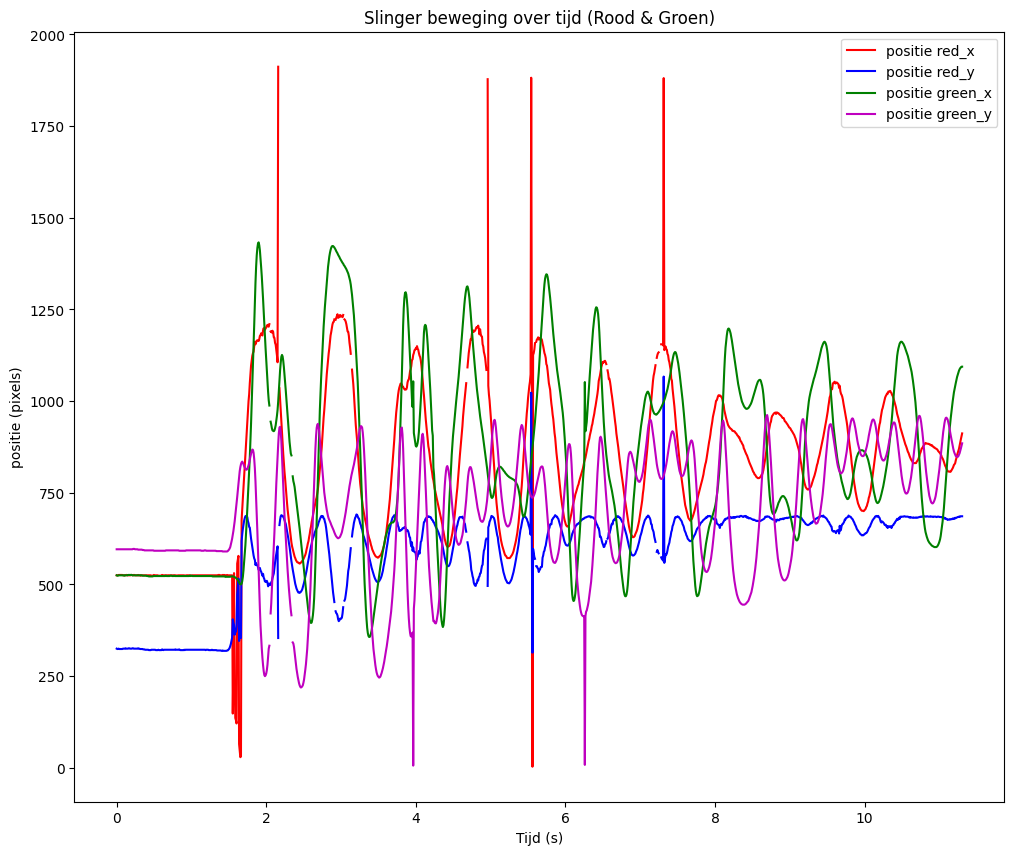

In [10]:
# 5 oktober 2026, tweede labsessie Slingerproef

# lezen data van de eerste slingertest en plotten van de x en y posities

# Lees de juiste CSV in die zojuist is aangemaakt
df = pd.read_csv("90gradentest3.csv") # of jouw gewenste bestandsnaam

tijd = df["time_s"].values
rx_array = df["red_x"].values      # Aangepast van "x" naar "red_x"
ry_array = df["red_y"].values      # Aangepast van "y" naar "red_y"
gx_array = df["green_x"].values    # Aangepast van "gx" naar "green_x"
gy_array = df["green_y"].values    # Aangepast van "gy" naar "green_y"

# Plot x en y positie van de rode stip
plt.figure(figsize=(12, 10))
plt.plot(tijd, rx_array, color='r', label = 'positie red_x')
plt.plot(tijd, ry_array, color='b', label = 'positie red_y')
plt.plot(tijd, gx_array, color='g', label = 'positie green_x')
plt.plot(tijd, gy_array, color='m', label = 'positie green_y')
plt.xlabel("Tijd (s)")
plt.ylabel("positie (pixels)")
plt.title("Slinger beweging over tijd (Rood & Groen)")
plt.legend()
plt.show()

# totale_positie = np.sqrt(x_array**2 + y_array**2) # wat is de totale positie ?

# plt.figure(figsize=(8, 5))
# plt.plot(tijd, totale_positie, color='b', linewidth=1.5)
# plt.xlabel("Tijd (s)")
# plt.ylabel("Totale positie / Afstand (pixels)")
# plt.title("Totale positie van de slinger uitgezet tegen de tijd")
# plt.grid(True, linestyle='--', alpha=0.6)
# plt.show()

# plt.figure(figsize=(8, 5))
# plt.plot(x_array[200:345], y_array[200:345], color='b', linewidth=1.5)
# plt.xlabel("x positie")
# plt.ylabel("y positie")
# plt.title("x tegen y")
# plt.grid(True, linestyle='--', alpha=0.6)
# plt.show()

In [5]:


# Functie om de indexen van uitschieters te vinden
def vind_uitschieters(data_array, drempel=200):
    uitschieter_indices = []
    for i in range(1, len(data_array)):
        # Bereken het absolute verschil met het vorige punt
        verschil = abs(data_array[i] - data_array[i-1])
        
        # Als het verschil groter is dan de drempel (200 pixels), sla de index van het laatste punt op
        if verschil > drempel:
            uitschieter_indices.append(i)
            
    return uitschieter_indices

# Voorbeeld: pas dit toe op je kolom (bijv. 'red_x')
kolom_naam = "red_x"
data_kolom = df[kolom_naam].values

indices = vind_uitschieters(data_kolom, drempel=200)

print(f"Aantal uitschieters gevonden in {kolom_naam}: {len(indices)}")
print("Indexen van het laatste punt bij de uitschieters:", indices)

Aantal uitschieters gevonden in red_x: 14
Indexen van het laatste punt bij de uitschieters: [184, 186, 187, 191, 194, 198, 256, 589, 657, 658, 659, 660, 867, 868]
